# Estado del arte: los modelos supervisores de pruebas de estrés, cópulas vine, crecimiento en riesgo y VAR bayesianos

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los cuadernos 02, 03 y 07 de este tema (las cópulas, la banda y las pruebas de validación)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este cuaderno puedes:

- decir cuál es el estado del arte publicado para las tres partes de un modelo de capital y estrés (los modelos supervisores de pruebas de estrés, los generadores de escenarios y la agregación de riesgos) y dónde está el caso frente a cada una;
- cuantificar el **riesgo de modelo** sobre el conjunto de modelos de agregación de la banda con las dos medidas de la literatura: el multiplicador de recargo y la medida relativa de Barrieu y Scandolo (2015), y la esperanza de peor caso dentro de un presupuesto de entropía relativa de Glasserman y Xu (2014);
- recalcular la primera desde la banda versionada y la segunda sobre un agregado simulado, y leer qué dice cada una que una sola cifra de capital no dice;
- decir cuáles de las herramientas del estado del arte tiene el motor (y cuáles corrió este cuaderno), cuáles difiere, y por qué los modelos supervisores no pueden replicarse aquí a una tasa de pérdida publicada.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un cuaderno nunca instala nada por sí mismo. Los identificadores de las pruebas del motor se imprimen tal como los escribe el motor. Sus mensajes y notas están escritos en inglés: el árbol inglés los imprime como están, y este árbol imprime una traducción desde una tabla del cuaderno que falla si el motor cambia el texto.

La celda siguiente importa lo que usa el cuaderno e imprime las versiones de los paquetes, para que las compares con las fijadas.

In [1]:
# Importar el motor y las ayudas, e imprimir las versiones de los paquetes que usa este cuaderno
import importlib.metadata as md
import json
from pathlib import Path

import numpy as np
import riskvalidation as rv
import matplotlib.pyplot as plt
from riskvalidation.aggregation import copulas as cop
from riskvalidation.aggregation import model_risk
from riskvalidation.portfolio import portfolio as rv_port
for name in ("riskvalidation", "numpy", "scipy", "matplotlib",):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Este cuaderno lee el bloque de agregación de **C18** (Banco Andino), como los cuadernos 01 a 03.

- **Propietario y licencia:** los documentos los escribe el pipeline sin conexión de este repositorio (`data-pipeline/pipeline/cases/c18/`) con el motor `riskvalidation` y se versionan en `data/derived/C18/`. Las trayectorias de escenario vienen de la Reserva Federal (dominio público), de la EBA y la ESRB (reproducción autorizada citando la fuente) y de la NGFS (solo derivado: únicamente las pocas variables que usa el caso). **Banco Andino es un banco sintético**: su cartera y su capital están calibrados a agregados públicos, y las trayectorias son trayectorias reales de Estados Unidos y de la zona euro trasladadas a su punto de partida, así que los satélites son una adaptación calibrada en EE. UU.
- **Estatus de verdad:** `synthetic-calibrated`. No hay respuesta publicada para el banco; las verificaciones de este cuaderno son recálculos de números versionados con el motor, no comparaciones con un resultado publicado.
- **Horneado con:** `riskvalidation` 0.8.1 (semilla 42), la versión que instala este cuaderno, así que se espera que un recálculo coincida hasta el redondeo.
- **Archivos leídos:** `data/derived/C18/baseline.json` (`outputs.aggregation`: marginales, banda, matriz de correlación y el bloque `model_risk` versionado con los resultados de Barrieu-Scandolo y Glasserman-Xu; y `outputs.backcast` para el ajuste fuera de tiempo de los satélites), `data/derived/C18/t-copula-baseline.json` (la referencia de Rosenberg y Schuermann) y `data/derived/C18/models-banco-andino.json` (`fit.aggregation.quantile_grid`).
- **Las marginales se reconstruyen desde las grillas de cuantiles versionadas, para un paso.** La medida de Glasserman-Xu necesita las pérdidas simuladas del agregado, que el documento no tiene, así que el paso 2 reconstruye las marginales del cuaderno 02 desde las grillas y simula el agregado gaussiano con la semilla del caso; los números versionados se imprimen al lado.

In [2]:
# El cuaderno está tres carpetas bajo la raíz del repositorio; un archivo ausente detiene el cuaderno y nombra su ruta
ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"


def read_json(relative):
    return json.loads((DERIVED / relative).read_text(encoding="utf-8"))


def sino(valor):
    # Mostrar un valor verdadero o falso como "sí" o "no"
    return "sí" if valor else "no"


print("carpeta derived encontrada:", sino(DERIVED.is_dir()))

baseline_doc = read_json("C18/baseline.json")
agg = baseline_doc["outputs"]["aggregation"]
R = np.array(agg["correlation"]["matrix"])
band = agg["band"]
print("filas de la banda:", len(band), "| bloque de riesgo de modelo versionado:", agg["model_risk"]["status"], "| horneado con riskvalidation", baseline_doc["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

carpeta derived encontrada: sí
filas de la banda: 8 | bloque de riesgo de modelo versionado: information-not-capital | horneado con riskvalidation 0.8.1 | instalado 0.8.1


## Método

### Paso 1: el riesgo de modelo sobre el conjunto de modelos de agregación

La banda del cuaderno 03 es un **conjunto de modelos** para una cantidad (el capital): la regla de la raíz cuadrada, la cópula gaussiana, tres cópulas t y las dos cotas. Una sola cifra oculta la dispersión entre ellos, y la literatura tiene medidas de esa dispersión (Barrieu y Scandolo, 2015). Sea $\rho(X_0)$ la medida bajo el **modelo de referencia**, y $\overline\rho$ y $\underline\rho$ su mayor y menor valor sobre el conjunto $\mathcal L$. Entonces

$$\mathrm{AM} = \frac{\overline\rho}{\rho(X_0)} - 1, \qquad \mathrm{RM} = \frac{\overline\rho - \rho(X_0)}{\overline\rho - \underline\rho} \in [0, 1].$$

El **multiplicador de recargo** AM generaliza el multiplicador de Basilea: multiplicar el capital de referencia por $1 + \mathrm{AM}$ llega al peor caso del conjunto. La **medida relativa** RM dice dónde está la referencia entre el mejor y el peor caso: 0 en el peor, 1 en el mejor. En el caso la referencia es la cópula gaussiana y el conjunto son las ocho filas de la banda, como información de sensibilidad, **no capital**. La celda siguiente recalcula ambas con `barrieu_scandolo` a partir de los capitales versionados, también a mano, y muestra al motor rechazando un índice de referencia fuera del conjunto.

In [3]:
# Multiplicador de recargo y medida relativa de Barrieu-Scandolo sobre las ocho filas de la banda, con el motor y a mano
capitals = [row["capital_clp_m"] for row in band]
labels = [(row["method"], row["nu"]) for row in band]
reference = labels.index(("gaussian-copula", None))
measures = model_risk.barrieu_scandolo(capitals, reference)
committed = agg["model_risk"]["barrieu_scandolo"]
print("modelo de referencia: cópula gaussiana, capital", round(measures.rho_x0, 1), "| peor del conjunto:", round(measures.rho_max, 1), "| mejor del conjunto:", round(measures.rho_min, 1))
print("AM (motor):", round(measures.am, 6), "| a mano:", round(max(capitals) / capitals[reference] - 1, 6), "| versionado:", round(committed["am"], 6))
print("RM (motor):", round(measures.rm, 6), "| a mano:", round((max(capitals) - capitals[reference]) / (max(capitals) - min(capitals)), 6), "| versionado:", round(committed["rm"], 6))
print("multiplicar el capital gaussiano por 1 + AM da", round(measures.rho_x0 * (1 + measures.am), 1), "= el peor caso")
try:
    model_risk.barrieu_scandolo(capitals, len(capitals))
except ValueError as err:
    print("un índice de referencia fuera del conjunto se rechaza:", err)

modelo de referencia: cópula gaussiana, capital 491973.5 | peor del conjunto: 823331.7 | mejor del conjunto: 118517.5
AM (motor): 0.673528 | a mano: 0.673528 | versionado: 0.673528
RM (motor): 0.470136 | a mano: 0.470136 | versionado: 0.470136
multiplicar el capital gaussiano por 1 + AM da 823331.7 = el peor caso
un índice de referencia fuera del conjunto se rechaza: reference_index must lie in [0, 7], got 8


### Paso 2: el peor caso dentro de un presupuesto de entropía

El conjunto de Barrieu y Scandolo es el conjunto de modelos que el analista escribió. Glasserman y Xu (2014) hacen otra pregunta: **¿cuán equivocado puede estar el modelo de referencia, de una manera medible, antes de que una cantidad cambie cuánto?** Se toma la ley base de una pérdida $V$ (aquí el agregado de la cópula gaussiana) y se consideran todas las leyes alternativas con razón de verosimilitud $m \ge 0$, $E[m] = 1$, cuya **entropía relativa** respecto de la base es a lo más un presupuesto $\eta$. La peor pérdida esperada es

$$\sup_{m \ge 0,\ E[m\log m] \le \eta} E[m\,V], \qquad m_\theta = \frac{e^{\theta V}}{E[e^{\theta V}]},$$

con $\theta > 0$ elegido de modo que la restricción de entropía se active: el peor caso **inclina** la muestra base hacia sus pérdidas grandes, de forma exponencial. Cuesta solo un reponderado de la simulación base. `glasserman_xu_worst_case(v, budget)` devuelve la inclinación $\theta$, la entropía alcanzada, la media base y la media del peor caso, y rechaza un presupuesto que la muestra no puede alcanzar (la entropía de una inclinación es a lo más $\log S$).

El caso usa el presupuesto $\eta = 0,05$ sobre el agregado gaussiano. La celda siguiente reconstruye las marginales del cuaderno 02 desde las grillas de cuantiles versionadas, simula el agregado con los ajustes del caso, corre el peor caso con cuatro presupuestos, lo imprime junto al resultado versionado y muestra el rechazo de un presupuesto inalcanzable.

In [4]:
# Reconstruir las marginales desde las grillas de cuantiles versionadas, simular el agregado gaussiano y luego el peor caso de Glasserman-Xu con cuatro presupuestos
LEVEL = 0.999
grid = read_json("C18/models-banco-andino.json")["fit"]["aggregation"]["quantile_grid"]
probs = np.array(grid["probabilities"])
draw_positions = (np.arange(1, 1_000_001) - 0.5) / 1_000_000
ppfs, samples = [], {}
for m, q in zip(agg["marginals"], grid["marginals"]):
    assert m["risk"] == q["risk"]
    quantiles = np.array(q["quantiles"])
    ppfs.append(lambda u, x=quantiles: np.interp(np.asarray(u, dtype=float), probs, x))
    samples[m["risk"]] = np.interp(draw_positions, probs, quantiles)
joint = cop.simulate_component_losses(ppfs, R, "gaussian", None, 1_000_000, 42, 100_000)
total = joint.sum(axis=1)
committed_gx = agg["model_risk"]["glasserman_xu"]
print("presupuesto del caso:", committed_gx["relative_entropy_budget"], "| versionado: base", round(committed_gx["baseline_clp_m"], 1), "peor caso", round(committed_gx["worst_case_clp_m"], 1), "theta", format(committed_gx["theta"], ".3e"))
print(f'{"presupuesto":>11s} {"theta":>10s} {"entropía":>8s} {"E[V] base":>14s} {"peor caso":>12s} {"razón":>6s}')
for budget in (0.01, 0.05, 0.1, 0.2):
    gx = model_risk.glasserman_xu_worst_case(total, budget)
    print(f"{budget:11.2f} {gx.theta:10.3e} {gx.relative_entropy:8.4f} {gx.baseline:14,.1f} {gx.worst_case:12,.1f} {gx.worst_case / gx.baseline:6.2f}")
# el motor escribe su mensaje en inglés; la tabla da su traducción y falla (KeyError) si el motor cambia el texto
TRADUCCION = {"budget 10.0 must be below the largest entropy attainable on the sample, log(S / k) = 3.91202 (at most log S = 3.91202)": "el presupuesto 10.0 debe ser menor que la mayor entropía alcanzable en la muestra, log(S / k) = 3.91202 (como máximo log S = 3.91202)"}
try:
    model_risk.glasserman_xu_worst_case(total[:50], 10.0)
except ValueError as err:
    print("un presupuesto que la muestra no puede alcanzar se rechaza:", TRADUCCION[str(err)])

presupuesto del caso: 0.05 | versionado: base 66898.5 peor caso 143201.8 theta 7.878e-07
presupuesto      theta entropía      E[V] base    peor caso  razón
       0.01  6.367e-07   0.0100       66,898.7     88,454.2   1.32
       0.05  7.878e-07   0.0500       66,898.7    143,206.7   2.14
       0.10  8.497e-07   0.1000       66,898.7    204,035.3   3.05
       0.20  9.114e-07   0.2000       66,898.7    317,194.7   4.74
un presupuesto que la muestra no puede alcanzar se rechaza: el presupuesto 10.0 debe ser menor que la mayor entropía alcanzable en la muestra, log(S / k) = 3.91202 (como máximo log S = 3.91202)


## Estado del arte

La investigación persistida (dossiers 05 y 06) declara la práctica en torno a cada parte del caso. La tabla la pone junto a lo que hace el caso, con la fuente y el estado de cada afirmación.

| Parte | La práctica publicada | En el caso y en el motor |
|---|---|---|
| **Modelos supervisores de pruebas de estrés** | La Reserva Federal publica ahora la documentación completa de sus modelos (otoño 2026, modelos de riesgo de crédito). La pérdida esperada corporativa es $PD \times LGD \times EAD$ por facilidad; el modelo de PD es un conjunto de 16 regresiones MCO de la PD de un proveedor sobre el diferencial BBB y su rezago de cuatro trimestres, estimadas 2006 a 2023; la LGD se estresa por el diferencial BBB, la EAD por un factor de equivalente de préstamo sobre datos del Shared National Credit; el PPNR tiene su propio conjunto de modelos 2026. | Cinco satélites MCO de tasas de castigo por tipo de préstamo sobre crecimiento del PIB y desempleo, ajustados 1985 a 2019 (cuaderno 04): una familia más simple y distinta. Los modelos de la Reserva Federal **no pueden replicarse a una tasa de pérdida publicada** desde el registro público, por lo cual el caso C19 sigue planificado (cuaderno 09). |
| **Abajo-arriba con restricciones** | El ejercicio de la EBA 2025 es una prueba de estrés abajo-arriba restringida: los bancos usan sus propios modelos con parámetros prescritos, con un balance estático y parámetros de referencia donde no existe un satélite adecuado (Nota Metodológica, párrafos 33 a 38 y 122 a 124). | Las reglas estáticas por párrafo se aplican y se prueban (cuaderno 05); el caso tiene un banco y ningún retador, así que abajo-arriba frente a arriba-abajo es una regla mostrada, no una comparación hecha (cuaderno 07). |
| **Generadores de escenarios** | VAR bayesianos con a priori de Minnesota (Litterman 1986; Banbura, Giannone y Reichlin 2010), VAR globales, crecimiento en riesgo con una densidad t asimétrica (Adrian, Boyarchenko y Giannone 2019) y un satélite de cuantiles en panel (Covas, Rump y Zakrajsek 2014). | El motor tiene el pronóstico condicional del VAR y el paso t asimétrico del crecimiento en riesgo (cuaderno 04); el paso de regresiones cuantílicas necesita `statsmodels`, ausente de este entorno; el BVAR de Minnesota y el satélite de cuantiles en panel están diferidos (ítem de backlog BL-078). |
| **Agregación de riesgos** | Rosenberg y Schuermann (2006): el riesgo total es más sensible a la mezcla de negocios que a las correlaciones entre riesgos, la elección de cópula tiene un efecto modesto, y la aproximación aditiva sobrestima el riesgo en cerca de 30 a 40 por ciento. El Joint Forum encontró los modelos de agregación "un trabajo en progreso" en los que los supervisores en general no confían (el comunicado de prensa del 21 de octubre de 2010, https://www.bis.org/press/p101021.htm, trae ambas frases). Las cópulas vine están disponibles sin conexión en `pyvinecopulib`. | La escalera desde la suma simple hasta el peor caso (cuadernos 01 a 03), y la referencia de Rosenberg y Schuermann leída junto al resultado. El motor tiene cópulas gaussiana y t y las formas cerradas de Clayton; **las cópulas vine no están en el motor** (BL-078) y `pyvinecopulib` no está en este entorno. |
| **Cuantificación del riesgo de modelo** | Barrieu y Scandolo (2015) y Glasserman y Xu (2014), como arriba; las medidas cuantitativas de riesgo de modelo son información de sensibilidad, nunca una cifra de capital regulatorio. | Ambas están en el motor y corren en los pasos 1 y 2; el caso las rotula `information-not-capital`. |

La celda siguiente lee los números propios del caso para cada fila de la tabla que se puede medir en los documentos versionados: el exceso aditivo frente al rango publicado, la dispersión de la banda, las medidas de riesgo de modelo y la retroproyección de los satélites.

In [5]:
# Medir en los documentos versionados lo que cada fila de la tabla permite medir
gaussian = next(r["capital_clp_m"] for r in band if r["method"] == "gaussian-copula")
simple_sum = agg["headline"]["capital_clp_m"]
reference = read_json("C18/t-copula-baseline.json")["outputs"]["rosenberg_schuermann"]
print("Rosenberg y Schuermann: exceso aditivo aquí", round(simple_sum / gaussian - 1, 4), "| rango publicado", reference["published_additive_overestimate"], "| dentro:", sino(reference["within_published_range"]))
diversified = [r["capital_clp_m"] for r in band if r["method"] in ("gaussian-copula", "t-copula")]
print("elección de cópula, dispersión de las filas con cópula sobre la fila gaussiana:", round(max(diversified) / gaussian - 1, 4), "| mezcla de negocios: capitales", {m["risk"]: round(m["ec_clp_m"] / simple_sum, 3) for m in agg["marginals"]})
print("dispersión de la banda: peor caso sobre cota inferior:", round(max(r["capital_clp_m"] for r in band) / min(r["capital_clp_m"] for r in band), 2), "| AM:", round(measures.am, 4), "| RM:", round(measures.rm, 4))
backcast = baseline_doc["outputs"]["backcast"]["per_loan_type"]
print("razones de máximo de la retroproyección de los satélites (predicho sobre realizado):", {b["fed_loan_type"]: round(b["metrics"]["peak_predicted"] / b["metrics"]["peak_realised"], 2) for b in backcast})
print("modelos de la Reserva Federal y de la EBA: no replicables aquí; cópulas vine y VAR bayesianos: no están en el motor")

Rosenberg y Schuermann: exceso aditivo aquí 0.3376 | rango publicado {'low': 0.3, 'high': 0.4} | dentro: sí
elección de cópula, dispersión de las filas con cópula sobre la fila gaussiana: 0.1228 | mezcla de negocios: capitales {'credit': 0.396, 'market': 0.431, 'irrbb': 0.111, 'operational': 0.063}
dispersión de la banda: peor caso sobre cota inferior: 6.95 | AM: 0.6735 | RM: 0.4701
razones de máximo de la retroproyección de los satélites (predicho sobre realizado): {'commercial-industrial': 4.55, 'commercial-real-estate': 13.14, 'residential': 252.13, 'credit-cards': 4.3, 'other-consumer': 2.09}
modelos de la Reserva Federal y de la EBA: no replicables aquí; cópulas vine y VAR bayesianos: no están en el motor


## Resultados

El gráfico dibuja la banda como múltiplo de la referencia gaussiana, con el multiplicador de recargo de Barrieu-Scandolo como la distancia al peor caso, y marca el rango que daría el exceso aditivo publicado para la suma simple.

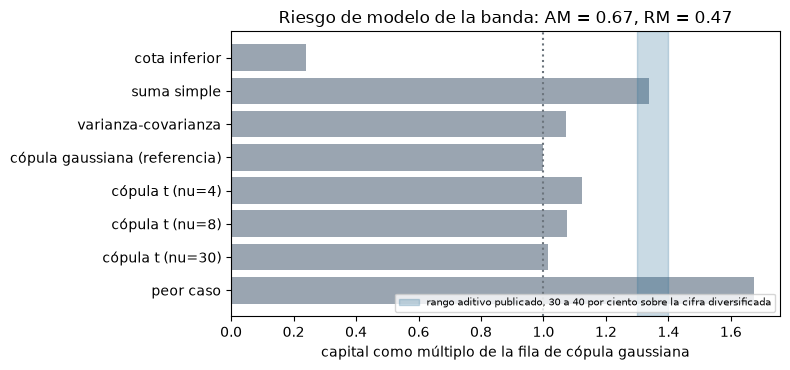

In [6]:
# Dibujar la banda como múltiplo de la referencia gaussiana, con el rango aditivo publicado para la suma simple sombreado
NAMES = {"lower-bound": "cota inferior", "simple-sum": "suma simple", "variance-covariance": "varianza-covarianza",
         "gaussian-copula": "cópula gaussiana (referencia)", "t-copula": "cópula t", "worst-case": "peor caso"}
names = [NAMES[r["method"]] + (f" (nu={r['nu']:g})" if r["nu"] else "") for r in band]
multiple = [r["capital_clp_m"] / gaussian for r in band]
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(names[::-1], multiple[::-1], color="#9aa5b1")
ax.axvspan(1.30, 1.40, color="#2a6f97", alpha=0.25, label="rango aditivo publicado, 30 a 40 por ciento sobre la cifra diversificada")
ax.axvline(1.0, color="#6c757d", linestyle=":")
ax.set_xlabel("capital como múltiplo de la fila de cópula gaussiana")
ax.set_title(f"Riesgo de modelo de la banda: AM = {measures.am:.2f}, RM = {measures.rm:.2f}")
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
plt.show()

- **El conjunto de modelos de agregación es amplio.** La referencia gaussiana es CLP 491.974 millones, y las ocho filas de la banda van de 118.518 (cota inferior) a 823.332 (peor caso), una razón de 6,95. El multiplicador de recargo es **0,6735**: multiplicar la referencia por 1,67 llega al peor caso. La medida relativa es **0,4701**: la referencia está al 47 por ciento del camino que baja del peor caso al mejor. El motor y las fórmulas a mano concuerdan con el bloque versionado al dígito, y un índice de referencia fuera del conjunto se rechaza.
- **El presupuesto de entropía convierte una duda de modelación en un número.** Sobre el agregado simulado desde las marginales versionadas, cuya media base es 66.899, la peor pérdida esperada dentro de un presupuesto de 0,01; 0,05; 0,10 y 0,20 es 88.454; 143.207; 204.035 y 317.195 (1,32; 2,14; 3,05 y 4,74 veces la base). Con el presupuesto del caso de 0,05 es el bloque versionado: 143.207 frente a 143.202, con una inclinación de 7,878e-7 en ambos. El peor caso crece más rápido que el presupuesto porque el agregado tiene cola pesada: cuanta más cola tiene la base, más puede mover su media un presupuesto dado. Un presupuesto que la muestra no puede alcanzar (entropía sobre $\log S = 3{,}91$) se rechaza.
- **Frente a la práctica publicada:** el exceso aditivo del caso, 33,76 por ciento, está dentro del 30 a 40 por ciento de Rosenberg y Schuermann; la cópula t con $\nu = 4$ queda 12,3 por ciento sobre la gaussiana, un efecto de cópula mayor que el "modesto" del artículo; y las razones de máximo de la retroproyección de los satélites, 2,09 a 252,13, dicen que la pérdida de crédito con estrés del caso descansa en satélites que fallan su propia validación (cuaderno 07).
- **Lo que el caso no tiene se declara:** los modelos de la Reserva Federal no pueden replicarse a una tasa de pérdida publicada desde el registro público, las cópulas vine y el BVAR de Minnesota no están en el motor, y el primer paso del crecimiento en riesgo necesita un paquete que este entorno no tiene.

Lo que este cuaderno no muestra: las cifras de Glasserman-Xu son sobre un agregado simulado desde una grilla de 1.961 puntos por marginal, que coincide con el bloque versionado hasta 0,01 por ciento y no hasta el dígito; la tabla del estado del arte es la de la investigación, con sus ítems NO VERIFICADOS marcados, no una revisión de literatura nueva; y ningún número en ella es un resultado regulatorio.

## Resumen

- La práctica publicada tiene tres capas: modelos supervisores (Reserva Federal, EBA), generadores de escenarios (BVAR, GVAR, crecimiento en riesgo, cuantiles en panel) y agregación (cópulas, vines, la cautela del Joint Forum); el caso implementa una familia de satélites más simple, las reglas estáticas de la EBA, un VAR y la mecánica t asimétrica, y la escalera gaussiana, t y de peor caso.
- El riesgo de modelo sobre la banda se mide con el multiplicador de recargo y la medida relativa de Barrieu y Scandolo, que el motor recalcula exactamente desde los capitales versionados, y con el peor caso de Glasserman-Xu dentro de un presupuesto de entropía, que necesita el agregado simulado y lo inclina hacia sus pérdidas grandes.
- Ambas medidas son información de sensibilidad para el validador, rotuladas `information-not-capital`, y dicen lo que una sola cifra de capital oculta.
- Lo que el motor no tiene se declara, no se oculta: cópulas vine, el BVAR de Minnesota, el satélite de cuantiles en panel y el primer paso del crecimiento en riesgo (necesita `statsmodels`); los modelos de la Reserva Federal no pueden replicarse a una tasa de pérdida publicada desde el registro público.

**Qué probar a continuación.** Cambia el modelo de referencia del paso 1 a la cópula t con $\nu = 4$ y mira cómo se mueven el multiplicador de recargo y la medida relativa; luego sigue con el cuaderno 09, que convierte la banda en una afirmación y lee la preparación declarada del caso.

## Referencias

- Glasserman, P. y Xu, X. (2014), Robust risk measurement and model risk, Quantitative Finance 14(1). https://doi.org/10.1080/14697688.2013.822989
- Barrieu, P. y Scandolo, G. (2015), Assessing financial model risk, European Journal of Operational Research 242(2). https://doi.org/10.1016/j.ejor.2014.10.032
- Rosenberg, J. V. y Schuermann, T. (2006), A general approach to integrated risk management with skewed, fat-tailed risks, Journal of Financial Economics 79(3). https://doi.org/10.1016/j.jfineco.2005.03.001
- Joint Forum (2010), Developments in modelling risk aggregation (avances en la modelación de la agregación de riesgos). https://www.bis.org/publ/joint25.pdf
- Banco de Pagos Internacionales (2010), comunicado de prensa del 21 de octubre de 2010 sobre el informe del Joint Forum Developments in modelling risk aggregation. https://www.bis.org/press/p101021.htm
- Board of Governors of the Federal Reserve System (2026), Supervisory Stress Test Model Documentation: Credit Risk Models, Fall 2026 (documentación de los modelos de crédito). https://www.federalreserve.gov/supervisionreg/files/fall-2026-credit-risk-models-description.pdf
- EBA (2025), 2025 EU-wide stress test, Methodological Note del 2025-01-20: el balance estático (párrafos 24, 33, 34 y 90 a 92). https://www.eba.europa.eu/sites/default/files/2025-01/0246e2f3-fa57-47d1-99f2-7a5b80cae509/2025%20EU-wide%20stress%20test%20-%20Methodological%20Note.pdf
- Adrian, T., Boyarchenko, N. y Giannone, D. (2019), Vulnerable growth, American Economic Review 109(4). https://doi.org/10.1257/aer.20161923
- Litterman, R. B. (1986), Forecasting with Bayesian vector autoregressions: five years of experience, Journal of Business and Economic Statistics 4(1). https://doi.org/10.1080/07350015.1986.10509491
- Banbura, M., Giannone, D. y Reichlin, L. (2010), Large Bayesian vector auto regressions, Journal of Applied Econometrics 25(1). https://doi.org/10.1002/jae.1137
- Covas, F., Rump, B. y Zakrajsek, E. (2014), el satélite de cuantiles en panel, y Pesaran, Schuermann y Weiner (2004), el VAR global, como los resume el dossier 05, H.2 (sin enlace: no se leyeron en la base de investigación de este repositorio).
- Este repositorio: `docs/contracts/engine/aggregation-api.md` (las funciones de riesgo de modelo).